# KernelSynth como canal exógeno no gerador multivariado

Este ensaio mede a entrega de batches de **16 exemplos × 192 passos × 6 canais** (contexto 96, futuro 96). Cada canal é AST ou KernelSynth, sorteado independentemente. Os canais KernelSynth não têm alvo da equation head; os AST podem depender dos seus lags. A figura usa a taxa sustentada depois de 16 batches de aquecimento, em 64 batches medidos por ponto, com oito workers fixos. A fila usa prefetch 2. Os tempos são desta máquina, sem GPU.

In [1]:
# Complete executed experiment record
import json
record = json.loads('{"config": {"workers": 8, "warmup": 16, "measured": 64, "seed": 20261119, "batch_size": 16, "channels": 6, "context": 96, "horizon": 96, "generated_steps": 192, "ast_treatment_probs": {"original": 0.0, "shao_wu": 0.5, "jacobian": 0.16666666666666666, "heaps": 0.3333333333333333}, "dependency": "random", "kernel_composition": "1 to 5 official-bank kernels", "factor_cache_size": 64, "blas_threads": 1, "base_multiseries": {"ast_config": {"minimum_operators": 1, "maximum_operators": 3, "num_series": 1, "minimum_lag": 1, "maximum_lag": 16, "max_degree": 4, "require_lag": true, "minimum_parameter_magnitude": 0.05, "maximum_parameter_magnitude": 0.9}, "channel_count_probs": {"6": 1.0}, "dependency_probs": {"random": 1.0}, "treatment_probs": {"original": 0.0, "shao_wu": 0.5, "jacobian": 0.16666666666666666, "heaps": 0.3333333333333333}, "max_external_sources": 2, "self_source_weight": 3.0, "allow_no_lags": true, "noise": {"std_range": [0.01, 0.1], "std_sampling": "uniform", "family_policy": "by_treatment"}, "target_gain": 0.8, "safety_factor": 0.95, "lag_sampling": {"minimum": 0.25, "maximum": 0.75, "tau": 1.0}}, "trajectory": {"generated_steps": 192, "initialization": {"name": "uniform", "kind": "uniform", "amplitude": 1.0, "offset": 0.0, "period": 48, "fraction": 1.0}, "resample_innovations": false}, "training": {"context_length": 96, "prediction_length": 96, "stride": 96, "batch_size": 16, "dtype": "float32", "layout": "batch_time_channel", "noise_target": "scale_and_family"}, "prefetch_factor": 2, "pin_memory": false}, "environment": {"python": "3.11.9", "platform": "Windows-10-10.0.19045-SP0", "cpu": "Intel64 Family 6 Model 158 Stepping 10, GenuineIntel", "logical_cpus": 8}, "results": [{"kernel_probability": 0.0, "actual_kernel_fraction": 0.0, "batch_seconds": [0.07113960012793541, 0.46606180001981556, 0.0015937997959554195, 0.23234050022438169, 0.0016361998859792948, 0.001811500173062086, 0.0016958999913185835, 1.203791500069201, 0.0017185001634061337, 0.3212007998954505, 0.0014495998620986938, 0.10821400000713766, 0.1961168001871556, 0.0018929000943899155, 0.001635099994018674, 1.097556399879977, 0.0014600001741200686, 0.39896610006690025, 0.0014969001058489084, 0.18892240012064576, 0.1349665999878198, 0.0020626999903470278, 0.0016352999955415726, 0.7515994999557734, 0.0014341999776661396, 0.30342629994265735, 0.0013631000183522701, 0.08774939994327724, 0.4524280000478029, 0.0017505001742392778, 0.001565700164064765, 0.3627885999158025, 0.04405649984255433, 0.5214301000814885, 0.18585210014134645, 0.061855999985709786, 0.29811810003593564, 0.0018535000272095203, 0.0017160000279545784, 0.531809100182727, 0.01956619997508824, 0.37542090006172657, 0.4753674999810755, 0.00148279988206923, 0.2654142000246793, 0.0019458001479506493, 0.001599400071427226, 0.4971237999852747, 0.0015759998932480812, 0.1240242999047041, 0.4399172000121325, 0.0012757000513374805, 0.37258809991180897, 0.0025903000496327877, 0.0026273000985383987, 0.4317456998396665, 0.0014399001374840736, 0.0869996000546962, 0.294662999920547, 0.06848419993184507, 0.1511902001220733, 0.0013972001615911722, 0.0014549000188708305, 0.47090870002284646], "median_seconds": 0.06981190002989024, "mean_seconds": 0.1897025703365216, "p95_seconds": 0.5302522501675412, "sustained_seconds_per_batch": 0.1898332156233664, "elapsed_including_startup_seconds": 25.114364300156012, "measured_batches": 64}, {"kernel_probability": 0.25, "actual_kernel_fraction": 0.2511393229166667, "batch_seconds": [0.5861527000088245, 0.7040182000491768, 0.0018066000193357468, 0.3603367998730391, 0.0015996000729501247, 0.0016828000079840422, 0.0019932000432163477, 0.0019350000657141209, 0.3587525999173522, 0.8004878000356257, 0.0016743000596761703, 0.2431675000116229, 0.0015577999874949455, 0.0019143999088555574, 0.0016767000779509544, 0.002236899919807911, 0.5124824999365956, 0.6189282999839634, 0.0015831999480724335, 0.42667899979278445, 0.0016771999653428793, 0.0018128999508917332, 0.0018841000273823738, 0.0019257999956607819, 0.6173811999615282, 0.4296872999984771, 0.0015244998503476381, 0.5545220000203699, 0.0014727998059242964, 0.0020129000768065453, 0.0017653999384492636, 0.0016789000947028399, 0.9218721999786794, 0.1812537000514567, 0.061092899879440665, 0.3975015999749303, 0.0018561999313533306, 0.0021051999647170305, 0.0020677000284194946, 0.0018201000057160854, 0.8145401999354362, 0.2828126000240445, 0.06470460002310574, 0.5014037999790162, 0.0019499999471008778, 0.0018190001137554646, 0.01586830010637641, 0.0016049002297222614, 0.8267106998246163, 0.0015410000924021006, 0.13920650002546608, 1.0329163998831064, 0.0016181999817490578, 0.0015326000284403563, 0.0020351000130176544, 0.0017395999748259783, 0.2037738999351859, 0.20136479986831546, 0.2553018999751657, 0.506681099999696, 0.001208599889650941, 0.0013777001295238733, 0.0011807999107986689, 0.0015718999784439802], "median_seconds": 0.0020240000449121, "mean_seconds": 0.19815694842327503, "p95_seconds": 0.8124323399504646, "sustained_seconds_per_batch": 0.19829781093721977, "elapsed_including_startup_seconds": 24.782912000082433, "measured_batches": 64}, {"kernel_probability": 0.5, "actual_kernel_fraction": 0.4967447916666667, "batch_seconds": [1.078230099985376, 0.5335695000831038, 0.0017923000268638134, 0.001966299954801798, 0.024179199943318963, 0.0017494999337941408, 0.0019153999164700508, 0.016649099998176098, 0.789619900053367, 0.9120672999415547, 0.0018313999753445387, 0.0018761998508125544, 0.0017648001667112112, 0.0020222000312060118, 0.0016809001099318266, 0.028020699974149466, 0.8401605000253767, 0.4211009999271482, 0.001759599894285202, 0.1346972999162972, 0.0020785999950021505, 0.002035799901932478, 0.0019739000126719475, 0.3094900001306087, 0.6543240000028163, 0.38832549983635545, 0.0018966000061482191, 0.1395449999254197, 0.1589416000060737, 0.0018710000440478325, 0.0017925999127328396, 0.017521699890494347, 0.985065600136295, 0.14632109995000064, 0.3443012998905033, 0.020263500045984983, 0.001741599990054965, 0.001687200041487813, 0.0018406999297440052, 0.09071430005133152, 0.9916174001991749, 0.02275650016963482, 0.46934999991208315, 0.0017081000842154026, 0.0018777998629957438, 0.0017462000250816345, 0.0019163999240845442, 0.256155600072816, 0.7463098999578506, 0.0015387998428195715, 0.49990119994618, 0.018738799961283803, 0.019759600050747395, 0.0023768998216837645, 0.0031975999008864164, 0.16644770000129938, 1.0151033999864012, 0.0016882999334484339, 0.6012865002267063, 0.024311899906024337, 0.0013117999769747257, 0.0014380000066012144, 0.0013094001915305853, 0.07331879995763302], "median_seconds": 0.018130249925889075, "mean_seconds": 0.203024240614468, "p95_seconds": 0.9741158551070835, "sustained_seconds_per_batch": 0.20317318124943995, "elapsed_including_startup_seconds": 25.89458750002086, "measured_batches": 64}, {"kernel_probability": 0.75, "actual_kernel_fraction": 0.7482096354166666, "batch_seconds": [1.5368882999755442, 0.05543829989619553, 0.0021164999343454838, 0.0018938002176582813, 0.0021377999801188707, 0.0018003999721258879, 0.002120800083503127, 0.0019251001067459583, 1.4549245000816882, 0.061138799879699945, 0.001603499986231327, 0.0018055001273751259, 0.0016732001677155495, 0.0019330999348312616, 0.001762300031259656, 0.0018444000743329525, 1.4989139998797327, 0.21909560007043183, 0.0025017999578267336, 0.0018863999284803867, 0.0018199998885393143, 0.0018596001900732517, 0.0016938000917434692, 0.0017078998498618603, 1.144178400048986, 0.253967999946326, 0.001843100180849433, 0.001988499891012907, 0.020993300015106797, 0.002244099974632263, 0.001789500005543232, 0.0017967000603675842, 1.7025568999815732, 0.0018465002067387104, 0.0021365999709814787, 0.00212309998460114, 0.001988000003620982, 0.0018776000943034887, 0.001961299916729331, 0.001932100160047412, 1.3648077000398189, 0.0016531997825950384, 0.0018901999574154615, 0.001858399948105216, 0.001832299865782261, 0.0018951001111418009, 0.001844900194555521, 0.02229949994944036, 1.3214369998313487, 0.0015912000089883804, 0.001482499996200204, 0.0014054998755455017, 0.0014134999364614487, 0.0015644999220967293, 0.0016701000276952982, 0.0017336998134851456, 1.3361337000969797, 0.0012135000433772802, 0.0014012001920491457, 0.0011317001190036535, 0.0009862000588327646, 0.0009439999703317881, 0.0009035000111907721, 0.0009995000436902046], "median_seconds": 0.0018686001421883702, "mean_seconds": 0.18874690157099394, "p95_seconds": 1.4414069800754072, "sustained_seconds_per_batch": 0.1888860765611753, "elapsed_including_startup_seconds": 25.396818600129336, "measured_batches": 64}], "provenance": {"git_head": "149621347c0e13669ad635d940ce03833b82bb61", "source_sha256": {"src/tsfmxai/generators/hybrid.py": "6b10b4a954c6889ffcf22841d640d9c8807dd93a380700a1176f3302de3a6775", "src/tsfmxai/generators/kernel_synth.py": "3f6690aa09518f8d4d1d98dff1a2a8446e3825e0069b9165bac0c0313e3bae2b", "src/tsfmxai/generators/multiseries.py": "ca0b950c07d50a8540e767e4e9745c0a1849d425c0920bf6d7fc7b04c3cb3af9", "src/tsfmxai/datasets/hybrid.py": "662c08658e763c44faa236907a23b275f44d4f27d42f12a9cefbd3bf9f27aa73", "src/tsfmxai/datasets/multiseries.py": "f0ec18e55357631eaf68f084bbc0329d3748d2c27f86c4ef1112102118c4ed6c", "src/tsfmxai/datasets/online.py": "af1ee71ebd3a3a5e6b9e4b1c3193a8403841a3bfd1eb969668bdd777ccc170b1", "scripts/benchmark_hybrid_batches.py": "0baa8661516cc307961f703b30f2e966d8b755eb9ff68e9629b72b58c4155265"}}, "question": "How does KernelSynth channel probability affect delivered batch time?", "hypothesis": "More KernelSynth channels may increase sustained batch time because GP factorization is more expensive than AST execution.", "scientific_summary": "Exploratory CPU-only generation benchmark. The kernel fraction is sampled per channel; reported realized fractions are measured. Factorization is cached per worker, but GP trajectories are fresh. The legacy AST builder also samples unused ASTs for KernelSynth channels. No Chronos forward or GPU stall is measured. This is not a speed comparison with TimePFN LMC: that runner generates 1024-point trajectories, caches them, extracts multiple windows, and its published cold timing also includes a GPU update. The present 208-point KernelSynth-like sampler uses the official kernel bank but is not the pinned TimePFN implementation. Observed sustained seconds/batch ranged from 0.1889 to 0.2032.", "reproduction": "From repository root with the recorded Python environment: python scripts/benchmark_hybrid_batches.py --output outputs/hybrid_benchmark.json --workers 8 --warmup 16 --measured 64; python scripts/record_hybrid_benchmark.py outputs/hybrid_benchmark.json"}')
for row in record['results']:
    print(f"p={row['kernel_probability']:.0%}, realized={row['actual_kernel_fraction']:.1%}, seconds/batch={row['sustained_seconds_per_batch']:.3f}, p95 wait={row['p95_seconds']:.3f}")

p=0%, realized=0.0%, seconds/batch=0.190, p95 wait=0.530
p=25%, realized=25.1%, seconds/batch=0.198, p95 wait=0.812
p=50%, realized=49.7%, seconds/batch=0.203, p95 wait=0.974
p=75%, realized=74.8%, seconds/batch=0.189, p95 wait=1.441


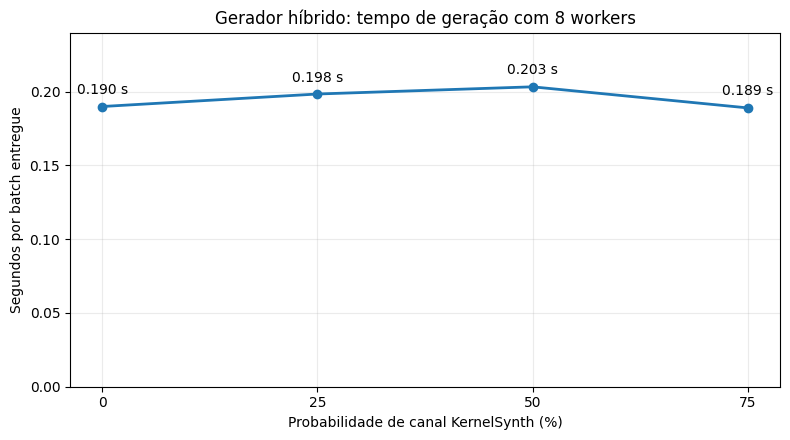

In [2]:
import matplotlib.pyplot as plt
rows = record['results']
x = [100 * r['kernel_probability'] for r in rows]
y = [r['sustained_seconds_per_batch'] for r in rows]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, y, marker='o', linewidth=2)
for xi, yi in zip(x, y):
    ax.annotate(f'{yi:.3f} s', (xi, yi), xytext=(0, 9),
                textcoords='offset points', ha='center')
ax.set(xlabel='Probabilidade de canal KernelSynth (%)',
       ylabel='Segundos por batch entregue',
       title='Gerador híbrido: tempo de geração com 8 workers')
ax.set_xticks(x)
ax.set_ylim(0, max(y) * 1.18)
ax.grid(alpha=.25)
fig.tight_layout()
plt.show()

## Interpretação

A curva mede **tempo por batch entregue** com o consumidor pedindo batches continuamente. A espera de `next()` pode ser pequena quando há itens prefetched; por isso usamos o tempo total dos 64 batches medidos dividido por 64. A preparação dos 16 batches iniciais e o início dos workers aparecem separadamente no registro. Cada ponto sorteia uma fração efetiva próxima, mas não idêntica, à probabilidade configurada. Este teste não mede a qualidade do forecasting.

**Não comparar diretamente com o tempo LMC anterior:** aqui usamos trajetórias de aproximadamente 208 pontos, uma janela por sistema, e nenhum passo de treino. O runner TimePFN usa trajetórias de 1.024 pontos, cache e múltiplas janelas por trajetória. Sua medida fria inclui atualização na GPU. Este caminho reproduz o banco de kernels em um sampler próprio, não o código fixado do TimePFN.